# Business Survival in Ireland 
#  Module: Statistics for Data Analytics - CA1
Student name: Valeria Cantu Angel
Student ID: 2026679

Dataset: CSO BRA36 - Enterprise Survival NACE Rev. 2
GitHub repository: 

# Research objective

To explore enterprise births and business survival in Ireland. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# Load the original data
df = pd.read_csv("BRA36.20261013T001012.csv", encoding="utf-8-sig")

#Inspect the dataset
print("Dataset shape:", df.shape)
df.info()

df.head()

Dataset shape: (80784, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80784 entries, 0 to 80783
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Statistic Label  80784 non-null  object 
 1   Year             80784 non-null  int64  
 2   Employment Size  80784 non-null  object 
 3   Activity         80784 non-null  object 
 4   UNIT             80784 non-null  object 
 5   VALUE            61434 non-null  float64
dtypes: float64(1), int64(1), object(4)
memory usage: 3.7+ MB


,Statistic Label,Year,Employment Size,Activity,UNIT,VALUE
0,Enterprise births in reference year,2019,All persons engaged size classes,Mining and Quarrying (B),Number,27.0
1,Enterprise births in reference year,2019,All persons engaged size classes,Manufacturing (C),Number,1237.0
2,Enterprise births in reference year,2019,All persons engaged size classes,"Electricity, Gas, Steam and Air Conditioning S...",Number,57.0
3,Enterprise births in reference year,2019,All persons engaged size classes,"Water Supply; Sewerage, Waste Management and R...",Number,57.0
4,Enterprise births in reference year,2019,All persons engaged size classes,Construction (F),Number,5151.0


## Data Preparation

Three numerical measures are selected: enterprise births,
persons engaged at birth and enterprises surviving one year.

Broad economic sectors are retained using the all-size total.
Detailed subsectors and individual size categories are not
added to these totals, avoiding double counting.

In [3]:
# Define the numerical measures and their shorter names
measure_names = {"Enterprise births in reference year":"Births","Persons engaged by enterprise births in reference year":"Persons engaged at birth","Enterprise births surviving one year to reference year":"One-year survivors"}

# Check that the required measures exist
assert set(measure_names).issubset(df["Statistic Label"].unique())

# Identify broad economic sectors
sector_endings = ("(B)", "(C)", "(D)", "(E)", "(F)", "(G)","(H)", "(I)", "(J)", "(K)", "(L)", "(M)","(N)", "(P)", "(Q)", "(R)")

# Select the measures, broad sectors and all-size totals
prepared_data = df.loc[df["Statistic Label"].isin(measure_names) & df["Activity"].str.endswith(sector_endings, na=False) & df["Employment Size"].eq("All persons engaged size classes")
].copy()

# Assign shorter measure names
prepared_data["Measure"] = (prepared_data["Statistic Label"].map(measure_names))

print("Selected measures:", prepared_data["Measure"].nunique())
print("Selected sectors:", prepared_data["Activity"].nunique())
print("Selected records:", len(prepared_data))

Selected measures: 3
Selected sectors: 16
Selected records: 288


### Birth Cohort Alignment

One-year survivors recorded in a reference year belong
to enterprises born in the previous year.

The measures are aligned by birth cohort. Cohorts from
2019 to 2023 are retained because their following-year
survival records fall within the available period.

In [4]:
# Initially assign the reference year as the birth cohort
prepared_data["Birth cohort"] = prepared_data["Year"]

# Assign survivors to the previous year's birth cohort
survival_rows = prepared_data["Measure"].eq("One-year survivors")

prepared_data.loc[survival_rows, "Birth cohort"] = (prepared_data.loc[survival_rows, "Year"] - 1)

# Check that each measurement has a unique key
assert not prepared_data.duplicated(
    ["Birth cohort", "Activity", "Measure"]).any()

# Arrange the three measures into separate columns
analysis_table = prepared_data.pivot(index=["Birth cohort", "Activity"],columns="Measure",values="VALUE").reset_index()

analysis_table.columns.name = None

# Retain cohorts with birth-year and follow-up coverage
analysis_table = analysis_table.loc[analysis_table["Birth cohort"].between(2019, 2023)].copy()

# Arrange the columns
analysis_table = analysis_table[["Birth cohort","Activity","Births","Persons engaged at birth","One-year survivors"]].sort_values(["Birth cohort", "Activity"]).reset_index(drop=True)

# Treat the cohort and economic activity as categorical groups
analysis_table["Birth cohort"] = (analysis_table["Birth cohort"].astype("category"))

analysis_table["Activity"] = (analysis_table["Activity"].astype("category"))

print("Prepared dataset shape:", analysis_table.shape)
analysis_table.head(10)

Prepared dataset shape: (80, 5)


,Birth cohort,Activity,Births,Persons engaged at birth,One-year survivors
0,2019,Accommodation and Food Service Activities (I),1937.0,10317.0,1619.0
1,2019,Administrative and Support Service Activities (N),1528.0,2840.0,1261.0
2,2019,"Arts, Entertainment and Recreation (R)",924.0,1425.0,692.0
3,2019,Construction (F),5151.0,7954.0,4111.0
4,2019,Education (P),896.0,1399.0,707.0
5,2019,"Electricity, Gas, Steam and Air Conditioning S...",57.0,36.0,55.0
6,2019,Financial and Insurance Activities (K),NaN,1640.0,926.0
7,2019,Human Health and Social Work Activities (Q),1287.0,4004.0,1067.0
8,2019,Information and Communication (J),1772.0,4606.0,1497.0
9,2019,Manufacturing (C),1237.0,1886.0,1029.0


In [9]:
#Calculate one-year business survival rate

analysis_table ["Survival Rate(%)"] = (analysis_table["One-year survivors"] / analysis_table["Births"]) * 100

#display the results
analysis_table.head(10)

,Birth cohort,Activity,Births,Persons engaged at birth,One-year survivors,Survival Rate(%)
0,2019,Accommodation and Food Service Activities (I),1937.0,10317.0,1619.0,83.582860
1,2019,Administrative and Support Service Activities (N),1528.0,2840.0,1261.0,82.526178
2,2019,"Arts, Entertainment and Recreation (R)",924.0,1425.0,692.0,74.891775
3,2019,Construction (F),5151.0,7954.0,4111.0,79.809746
4,2019,Education (P),896.0,1399.0,707.0,78.906250
5,2019,"Electricity, Gas, Steam and Air Conditioning S...",57.0,36.0,55.0,96.491228
6,2019,Financial and Insurance Activities (K),NaN,1640.0,926.0,NaN
7,2019,Human Health and Social Work Activities (Q),1287.0,4004.0,1067.0,82.905983
8,2019,Information and Communication (J),1772.0,4606.0,1497.0,84.480813
9,2019,Manufacturing (C),1237.0,1886.0,1029.0,83.185125


In [12]:
print(analysis_table.columns.tolist())

['Birth cohort', 'Activity', 'Births', 'Persons engaged at birth', 'One-year survivors', 'Survival Rate(%)']


In [14]:
# Summary of survival rates

print(analysis_table["Survival Rate(%)"].describe())

# Check missing values

print("\nMissing values:")
print(analysis_table["Survival Rate(%)"].isnull().sum())

# Check minimum and maximum

print("\nMinimum survival rate:",
      analysis_table["Survival Rate(%)"].min())

print("\nMaximum survival rate:",
      analysis_table["Survival Rate(%)"].max())

count    78.000000
mean     80.589202
std       4.953014
min      66.666667
25%      77.726020
50%      80.673458
75%      83.052953
max      96.969697
Name: Survival Rate(%), dtype: float64

Missing values:
2

Minimum survival rate: 66.66666666666666

Maximum survival rate: 96.96969696969697


In [17]:
# Identify missing survival rate observations

missing_data = analysis_table[analysis_table["Survival Rate(%)"].isnull()]

#Display missing observations

display(missing_data)

,Birth cohort,Activity,Births,Persons engaged at birth,One-year survivors,Survival Rate(%)
6,2019,Financial and Insurance Activities (K),NaN,1640.0,926.0,NaN
22,2020,Financial and Insurance Activities (K),NaN,3681.0,1559.0,NaN


In [18]:
print("Missing births:")
print(analysis_table["Births"].isnull().sum())

print("\nZero births:")
print((analysis_table["Births"] == 0).sum())

Missing births:
2

Zero births:
0


In [19]:
#Identify observations with missing business births 

missing_births = analysis_table[analysis_table["Births"].isnull()]

display(missing_births)

,Birth cohort,Activity,Births,Persons engaged at birth,One-year survivors,Survival Rate(%)
6,2019,Financial and Insurance Activities (K),NaN,1640.0,926.0,NaN
22,2020,Financial and Insurance Activities (K),NaN,3681.0,1559.0,NaN


In [21]:
#Check missing values in all numerical variables

print(analysis_table[["Births", "Persons engaged at birth","One-year survivors","Survival Rate(%)",]].isnull().sum())

Births                      2
Persons engaged at birth    5
One-year survivors          0
Survival Rate(%)            2
dtype: int64


# Missing Values and Data Quality

The prepared dataset contains 80 observations distributed across 16 economic sectors and five cohorts based on the year of establishment (2019-2023)

Two missing values were identified in the "Enterprise Births" variable, both pertaining to the financial and insurance activities sector, it was not possible to calculate the first year survival rate for these observations.

However, five missing values were detected in the "Persons Engaged at Birth" variable, these do not directly affect the calculation of enterprise survival rates.

The missing values were left as they are rather than being replaced with zeros or estimates to avoid introducing information. Statistical calculations related to survival rates exclude observations for which the necessary data are unavailable.

In [25]:
#Calculate avarage survival rate by economic sector

sector_survival = (analysis_table.groupby("Activity", observed=True)["Survival Rate(%)"].mean().sort_values())

print(sector_survival)

Activity
Construction (F)                                                            76.369132
Real Estate Activities (L)                                                  77.357909
Financial and Insurance Activities (K)                                      77.851454
Mining and Quarrying (B)                                                    78.660804
Arts, Entertainment and Recreation (R)                                      79.170691
WholeSale and Retail Trade; Repair of Motor Vehicles and Motorcycles (G)    79.199984
Transportation and Storage (H)                                              79.633286
Manufacturing (C)                                                           79.776692
Administrative and Support Service Activities (N)                           79.813155
Education (P)                                                               80.155850
Information and Communication (J)                                           80.239665
Professional, Scientific and Technical Activi

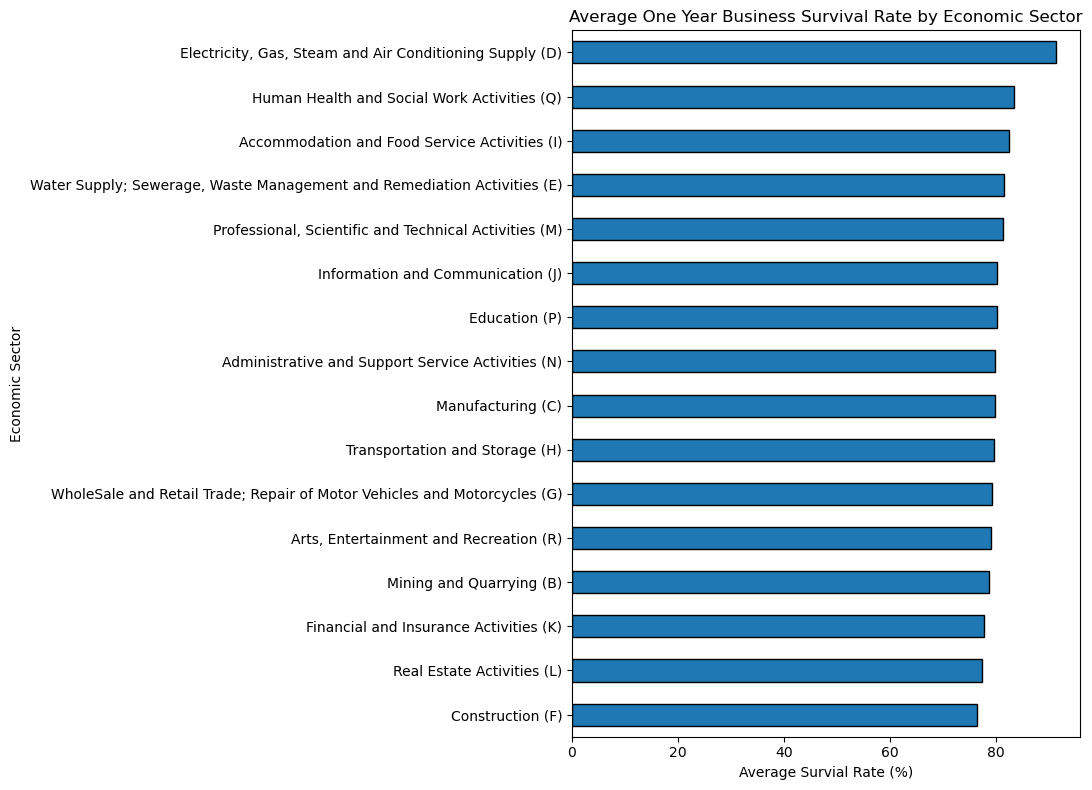

In [26]:
#Create the first statistical graph

plt.figure(figsize=(11, 8))

sector_survival.plot(kind="barh",edgecolor="black")
plt.title("Average One Year Business Survival Rate by Economic Sector")

plt.xlabel("Average Survial Rate (%)")
plt.ylabel("Economic Sector")

plt.tight_layout()
plt.show()

In [27]:
#Identify the highest and lowest survival rates

print("Lowest survival rate:")
print(sector_survival.head(3))

print("\nHighest survival rate:")
print(sector_survival.tail(3))

Lowest survival rate:
Activity
Construction (F)                          76.369132
Real Estate Activities (L)                77.357909
Financial and Insurance Activities (K)    77.851454
Name: Survival Rate(%), dtype: float64

Highest survival rate:
Activity
Accommodation and Food Service Activities (I)              82.560032
Human Health and Social Work Activities (Q)                83.351188
Electricity, Gas, Steam and Air Conditioning Supply (D)    91.317174
Name: Survival Rate(%), dtype: float64


# Business Survival Across Economic Sectors

The analysis reveals variations in average one year business rates across the 16 economic sectors examined. The electricity, gas, stream, and air conditioning supply sector recorded the highest average survival rate at 91.31%, while the construction sector showed the lowest 76.36%. 

The gap between these sectors was approximately 14.95 percentage points. Real estate activities, as well as financial and insurance activities, also exhibited relatively low average survival rate: 77.35% and 77.85% respectively.

These findings indicate that business survival patterns vary according to economic activity. However, the results reflect average survival rates at the sectoral level based on available cohorts of newly created businesses and do not determine the underlying causes of these differences.

In [28]:
#Remove observations with missing values in the variables

valid_data = analysis_table.dropna(subset=["Births", "One-year survivors"]).copy()

#Calculate survival rate by birth cohort

cohort_survival = (valid_data.groupby("Birth cohort", observed=True)[["Births", "One-year survivors"]].sum())

cohort_survival["Survival Rate(%)"] = (cohort_survival["One-year survivors"] / cohort_survival["Births"]) * 100

In [29]:
display(cohort_survival)

,Births,One-year survivors,Survival Rate(%)
Birth cohort,,,
2019,24193.0,19674.0,81.321043
2020,32497.0,26054.0,80.173554
2021,35586.0,27673.0,77.763727
2022,45380.0,36111.0,79.574703
2023,44961.0,35191.0,78.270056


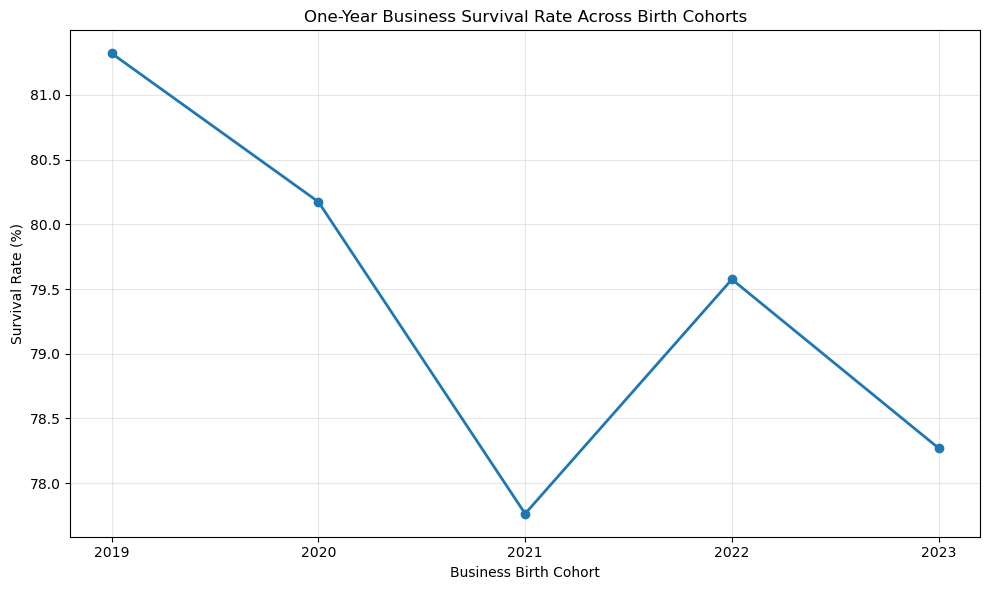

In [30]:
# Graph 2: Survival rate across birth cohorts

plt.figure(figsize=(10, 6))

plt.plot(cohort_survival.index.astype(str), cohort_survival["Survival Rate(%)"], marker="o",linewidth=2)

plt.title("One-Year Business Survival Rate Across Birth Cohorts")
plt.xlabel("Business Birth Cohort")
plt.ylabel("Survival Rate (%)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Business Survival Trends

An analysis of first year business survival rates, covering founding cohorts from 2019 to 2023 reveals a variable pattern. The 2019 cohort recorded the highest survival rate around 81.32% while the lowest was observed in 2021 at around 77.76%

Following the decline in 2021, survival rates partially recovered in 2022, only to decrease again in 2023, these findings indicate that business survival rates varied across the five cohorts, showing no consistent upward or downward trend.

In [31]:
#Display exact survival rates by birth cohort

print(cohort_survival["Survival Rate(%)"].round(2))

Birth cohort
2019    81.32
2020    80.17
2021    77.76
2022    79.57
2023    78.27
Name: Survival Rate(%), dtype: float64


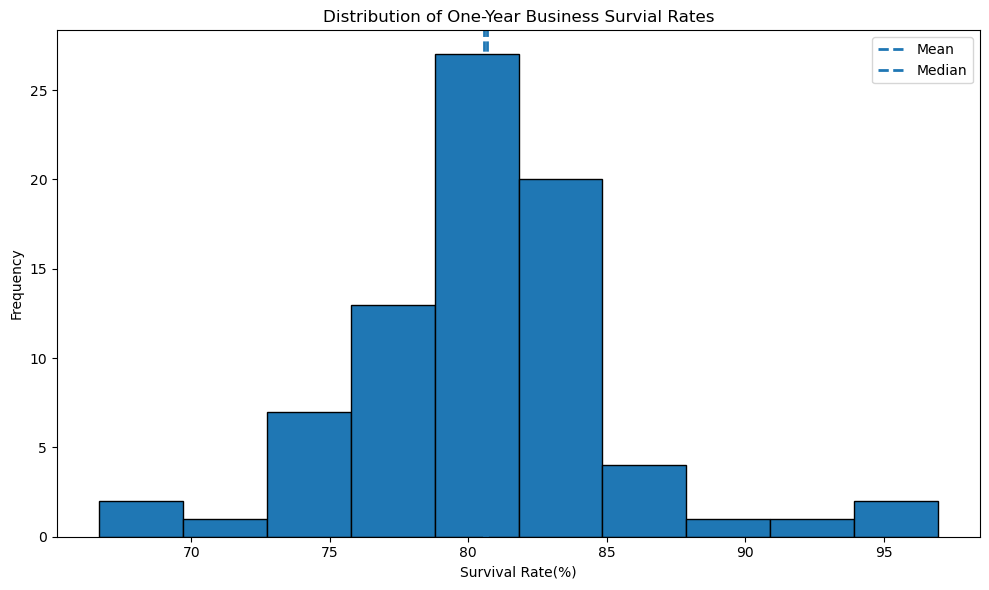

In [32]:
#Graph 3: Distribution of business survival rates

plt.figure(figsize=(10,6))

plt.hist(analysis_table["Survival Rate(%)"].dropna(), bins=10, edgecolor="black")

plt.axvline(analysis_table["Survival Rate(%)"].mean(), linestyle="--", linewidth=2, label="Mean")

plt.axvline(analysis_table["Survival Rate(%)"].median(), linestyle="--", linewidth=2, label="Median")

plt.title("Distribution of One-Year Business Survial Rates")
plt.xlabel("Survival Rate(%)")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()
plt.show()